# 03 — Target encoding: biến "món gì được mua" thành feature

## Ý tưởng

EDA cho thấy tín hiệu mạnh nhất nằm ở **sản phẩm khách đã mua**. Ta biến mỗi sản phẩm thành
một con số "độ tuổi người mua đặc trưng", rồi lấy trung bình theo lịch sử mua của khách.

Đây là **target encoding** (mean encoding): dùng chính nhãn để tạo feature.

$$\text{enc}(c) = \frac{\sum_{i \in \text{train},\ i\ \text{mua}\ c} \text{age}_i + \alpha\, \text{prior}}{n_c + \alpha},
\qquad \text{feature}(u) = \frac{\sum_{c\ \text{mà}\ u\ \text{mua}} \text{enc}(c)}{\#\{c\}}$$

trong đó `prior` = median age của tập train, `α` là hệ số làm trơn Bayes:

- `n_c` nhỏ (sản phẩm hiếm) → `enc(c)` bị kéo về `prior`;
- `n_c` lớn → `enc(c)` tiến gần tuổi trung bình thật của người mua.

## ⚠️ Cái bẫy phải tránh: rò rỉ nhãn (target leakage)

Nếu ta tính `enc(c)` trên **toàn bộ** dữ liệu rồi đánh giá cross-validation, mỗi khách trong tập
validation đã góp nhãn của chính họ vào encoding → điểm CV sẽ **đẹp giả tạo**.

Cách đúng: trong mỗi fold, **chỉ** dùng nhãn của khách thuộc tập train của fold đó.

In [1]:
import sys
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# Notebook có thể được mở từ thư mục notebooks/ hoặc từ gốc repo
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

DATA = ROOT / "data"
CUSTOMERS = DATA / "customers.csv"
ARTICLES = DATA / "articles.csv"
TXN = DATA / "transactions_train.csv"
ARTIFACTS = ROOT / "artifacts"
OUTPUTS = ROOT / "outputs"
REPORTS = ROOT / "reports"

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True, "grid.alpha": 0.3})
print("polars", pl.__version__, "| numpy", np.__version__, "| ROOT =", ROOT)

polars 2.1.0 | numpy 2.3.5 | ROOT = E:\download\age_imputation


In [2]:
import lightgbm as lgb
from sklearn.model_selection import KFold

import src.config as C
from src.dataset import load
from src.target_encoding import TargetEncoder

X, y, base_names = load()
print(f"X tĩnh: {X.shape} | nhãn: có {(~np.isnan(y)).sum():,}, thiếu {np.isnan(y).sum():,}")

X tĩnh: (1371980, 96) | nhãn: có 1,356,119, thiếu 15,861


## Ví dụ nhỏ để hiểu công thức

Giả sử một sản phẩm có 3 người mua tuổi 20, 30, 40 và prior = 32, α = 10:

- trung bình thô: (20 + 30 + 40) / 3 = 30
- có làm trơn: (90 + 10 × 32) / (3 + 10) = 410 / 13 ≈ **31,5** (bị kéo về prior vì chỉ có 3 người)

Với sản phẩm có 5.000 người mua, làm trơn gần như không ảnh hưởng.

In [3]:
def smoothed_encoding(ages, prior: float, alpha: float) -> float:
    ages = np.asarray(ages, dtype=float)
    return float((ages.sum() + prior * alpha) / (ages.size + alpha))


prior_demo = 32.0
for ages in [[20, 30, 40], [20, 30, 40] * 1000]:
    print(f"n = {len(ages):>5} | trung bình thô = {np.mean(ages):6.2f} | có làm trơn = {smoothed_encoding(ages, prior_demo, 10):6.2f}")

n =     3 | trung bình thô =  30.00 | có làm trơn =  31.54
n =  3000 | trung bình thô =  30.00 | có làm trơn =  30.01


## 9 đặc trưng target encoding

`TargetEncoder` tính **trên từng fold**, chỉ từ nhãn của tập train:

| Feature | Mức | Hệ số α | Ghi chú |
|---|---|---|---|
| `te_article` | 105.542 sản phẩm | 10 | tín hiệu mạnh nhất |
| `te_department_no` | 627 khoa hàng | 20 | |
| `te_product_type_no` | 647 loại sản phẩm | 20 | |
| `te_index_name` | 11 nhóm chính | 20 | Ladieswear / Divided / Menswear / Baby... |
| `te_section_name` | 594 khu vực trưng bày | 20 | |
| `te_product_type_name` | 645 tên loại | 20 | |
| `art_enc_std` | — | — | độ phân tán "độ tuổi" các món đã mua |
| `art_enc_max`, `art_enc_min` | — | — | món "già" nhất / "trẻ" nhất khách từng mua |

Vì sao cần `std`/`max`/`min`? Hai khách cùng tuổi trung bình 35 nhưng một người mua rất nhất quán
(30–40), người kia mua hỗn hợp (18–60) — độ tin cậy khác nhau.

In [4]:
import time

encoder = TargetEncoder(y.size)
print("Đã nạp:", encoder.cust_article.shape, "cặp khách×sản phẩm")
print("các mức encoding:", list(encoder.levels))
print("tên feature:", encoder.names)

Đã nạp: (1371980, 105540) cặp khách×sản phẩm
các mức encoding: ['c_department_no', 'c_product_type_no', 'c_index_group_name', 'c_index_name', 'c_garment_group_name', 'c_section_name', 'c_product_type_name']
tên feature: ['te_article', 'te_department_no', 'te_product_type_no', 'te_index_name', 'te_section_name', 'te_product_type_name', 'art_enc_std', 'art_enc_max', 'art_enc_min']


## Minh chứng chống rò rỉ: encoding fold 1 chỉ thấy nhãn của tập train

Ta lấy fold 1 của cùng `KFold(5, shuffle=True, random_state=42)` như notebook 04, tính encoding,
rồi kiểm tra: với một khách trong tập **validation**, giá trị `te_article` của họ **không** phụ thuộc
nhãn của chính họ. Cách kiểm tra thực nghiệm: đổi nhãn của một khách validation và xem encoding
của khách đó có thay đổi không (nếu đúng thì không đổi, vì nhãn đó không được dùng).

In [5]:
labeled = np.flatnonzero(~np.isnan(y))
kf = KFold(n_splits=C.N_SPLITS, shuffle=True, random_state=C.RANDOM_STATE)
tr_pos, va_pos = next(iter(kf.split(labeled)))
tr_idx, va_idx = labeled[tr_pos], labeled[va_pos]

train_mask = np.zeros(y.size, bool)
train_mask[tr_idx] = True

t0 = time.time()
te = encoder.transform(train_mask, y)
print(f"encoding 1.371.980 khách x {te.shape[1]} feature trong {time.time() - t0:.1f}s")
print("NaN:", int(np.isnan(te).sum()))

# --- kiểm tra rò rỉ: đổi nhãn của 200 khách validation rồi tính lại ---
probe = va_idx[:200]
y_perturbed = y.copy()
y_perturbed[probe] = 99.0
te_perturbed = encoder.transform(train_mask, y_perturbed)
same = np.allclose(te[probe], te_perturbed[probe])
print(f"Nhãn của khách validation có ảnh hưởng encoding của chính họ? {'CÓ (rò rỉ!)' if not same else 'KHÔNG (an toàn)'}")
assert same, "Phát hiện rò rỉ nhãn!"

encoding 1.371.980 khách x 9 feature trong 2.1s
NaN: 0


Nhãn của khách validation có ảnh hưởng encoding của chính họ? KHÔNG (an toàn)


## Encoding có thực sự mang tín hiệu?

Vẽ `te_article` của khách (tính từ fold train) so với tuổi thật của họ trên tập validation.
Nếu tín hiệu mạnh, đám mây điểm sẽ dốc lên rõ rệt.

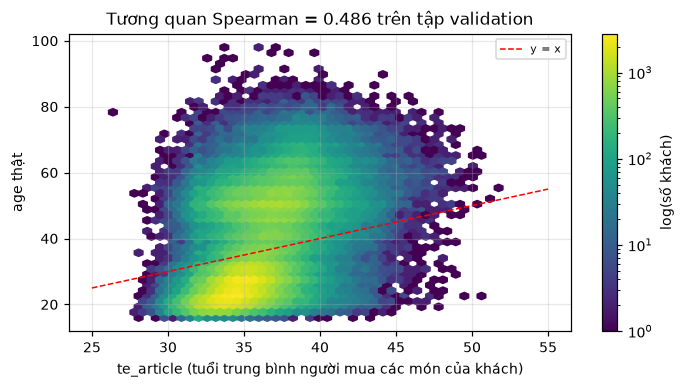

rho = 0.486
MAE nếu chỉ dùng te_article: 11.39 tuổi (median toàn cục: 12.06)


In [6]:
from scipy.stats import spearmanr

te_col = encoder.names.index("te_article")
x_te = te[va_idx, te_col]
y_va = y[va_idx]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
hb = ax.hexbin(x_te, y_va, gridsize=45, cmap="viridis", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax, label="log(số khách)")
ax.plot([25, 55], [25, 55], "r--", lw=1, label="y = x")
ax.set_xlabel("te_article (tuổi trung bình người mua các món của khách)")
ax.set_ylabel("age thật")
ax.set_title(f"Tương quan Spearman = {spearmanr(x_te, y_va).statistic:.3f} trên tập validation")
ax.legend(fontsize=7)
plt.tight_layout()
plt.show()

print(f"rho = {spearmanr(x_te, y_va).statistic:.3f}")
print(f"MAE nếu chỉ dùng te_article: {np.abs(x_te - y_va).mean():.2f} tuổi "
      f"(median toàn cục: {np.abs(np.median(y[tr_idx]) - y_va).mean():.2f})")

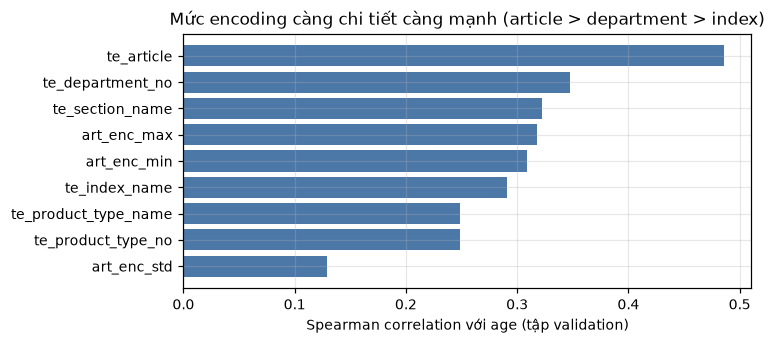

  te_article               +0.486
  te_department_no         +0.348
  te_section_name          +0.322
  art_enc_max              +0.318
  art_enc_min              +0.309
  te_index_name            +0.291
  te_product_type_name     +0.248
  te_product_type_no       +0.248
  art_enc_std              +0.129


In [7]:
# Tầm quan trọng tương đối của từng mức encoding (tương quan đơn biến với age trên validation)
rhos = {name: float(spearmanr(te[va_idx, j], y_va).statistic) for j, name in enumerate(encoder.names)}

order = sorted(rhos, key=lambda k: -abs(rhos[k]))
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.barh(order[::-1], [rhos[k] for k in order[::-1]], color="#4C78A8")
ax.set_xlabel("Spearman correlation với age (tập validation)")
ax.set_title("Mức encoding càng chi tiết càng mạnh (article > department > index)")
plt.tight_layout()
plt.show()

for k in order:
    print(f"  {k:<24} {rhos[k]:+.3f}")

**Đọc kết quả:** `te_article` có tương quan ~0,47–0,49 với tuổi — cao gấp 3 lần mọi feature RFM,
và tự nó đã cho MAE ~11,4 tuổi (so với 12,1 của median). Các mức thô hơn
(`te_index_name`, `te_section_name`) yếu hơn nhưng bổ sung thông tin cho những khách mua ít món
hoặc món hiếm.

## Tóm tắt: thiết kế chống rò rỉ

1. `TargetEncoder.transform(train_mask, y)` nhận **mặt nạ tập train** của fold → chỉ dùng nhãn
   của khách trong tập đó.
2. Encoding được tính lại **5 lần** (mỗi fold một lần) trong notebook 04.
3. Model cuối cùng dùng encoding tính trên **toàn bộ** khách có nhãn (hợp lệ vì đây là lúc dự đoán
   cho khách chưa có nhãn).
4. Kiểm chứng bằng thực nghiệm: đổi nhãn khách validation → encoding của họ không đổi.

➡️ Tiếp theo: **04_training.ipynb** — cross-validation, LightGBM, đánh giá.